# Frap Analysis
This notebook contains the Frap analysis code for Figure 2

In [30]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import scipy.optimize as opt 
import glob
from scipy.stats import sem
import matplotlib
cmap = matplotlib.colors.LinearSegmentedColormap.from_list("", ["#2e4185ff","#E7872B"]) ##FF9B00","#2E4185"]
from sklearn.metrics import r2_score
from matplotlib.colors import LogNorm, Normalize

In [2]:
# Meta data conferims that it is 5sec between messuments


In [3]:
def csv2data(path,ele='-',cell=0):
    t = pd.read_csv(path)
    t = t.loc[0:70]
    
    pre_bleach_reff  = np.mean(t.loc[0:2]['total'] - t.loc[0:2]['background'])
    pre_bleach_ROI  = np.mean(t.loc[0:2]['bleach'] - t.loc[0:2]['background'])
    
    norm_reff   = pre_bleach_reff/(t['total'] - t['background'])
    norm_ROI = (t['bleach'] - t['background'])/pre_bleach_ROI
    t['norm_reff'] = norm_reff*norm_ROI#t['total']- t['background']
    t['norm_full'] = 100*(t['norm_reff']-t['norm_reff'][3])/(t['norm_reff'][0] -t['norm_reff'][3])
    t['mdSAM']  = ele
    t['cell']  = cell
    t['time_n'] = np.NaN
    c = 0
    for i in t.index:
        t.loc[i,'time_n'] = c 
        c = c+5
#    t['time_n'] = [i+5 for i in range(len(t))]
    return t.loc[3:,['time','time_n','norm_full','mdSAM','cell']]

In [4]:
def prisim(t,Y0,Plateau,K):
    '''fitting recovery 
     - I_zero: Bottom
     - a: 
     - b: beta '''
    return Y0 + (Plateau-Y0)*(1-np.exp(-K*t))
def tau_function(t,I_zero,a,b):
    '''fitting recovery 
     - I_zero: Bottom
     - a: 
     - b: beta '''
    return I_zero - a*(np.exp(-b*t))

def tau_function_v2(t,A,tau):#y(t)=A⋅(1−e−τ⋅t)
    '''fitting recovery 
     - I_zero: Bottom
     - a: 
     - b: beta '''
    return A*(1-np.exp(-tau*t))
#Y=Y0 + (Plateau-Y0)*(1-exp(-K*x))

def prisim_v2(t,Plateau,K):
    '''fitting recovery 
     - I_zero: Bottom
     - a: 
     - b: beta '''
    return  (Plateau)*(1-np.exp(-K*t))

In [6]:
df = pd.DataFrame()
for c in enumerate(glob.glob('/Users/aelazar/notebooks_for_paper/FRAP/fiji_data_prossess/csvs/*.csv')):
#    print(c)
    df = pd.concat([df,csv2data(c[1],ele= '+',cell =c[0])],ignore_index=True)
for c in enumerate(glob.glob('/Users/aelazar/notebooks_for_paper/FRAP/fiji_data_prossess/csvs/dAPP/*.csv')):
#    print(c)
    df = pd.concat([df,csv2data(c[1],ele= '-',cell =c[0])],ignore_index=True)
for c in enumerate(glob.glob('/Users/aelazar/notebooks_for_paper/FRAP/fiji_data_prossess/csvs/APP2P/*.csv')):
#    print(c)
    df = pd.concat([df,csv2data(c[1],ele= '2P',cell =c[0])],ignore_index=True)
df['time_post_bleach'] =df['time_n']-15

In [7]:
def fit_prisim(mdSAM='-'):
    x_data = df[df.mdSAM==mdSAM].loc[:,['norm_full','time_post_bleach']].groupby(['time_post_bleach']).mean().index
    y_data = df[df.mdSAM==mdSAM].loc[:,['norm_full','time_post_bleach']].groupby(['time_post_bleach']).mean().norm_full
    y_std = df[df.mdSAM==mdSAM].loc[:,['norm_full','time_post_bleach']].groupby(['time_post_bleach']).std().norm_full
    fit_, covar_ = opt.curve_fit(prisim, x_data[1:], y_data[1:],
                               sigma = y_std[1:],
                               absolute_sigma = True,maxfev=100000)
#print(best_fit_ab)
    sigma_abs = np.sqrt(np.diagonal(covar_))
    y_pred = prisim(x_data, *fit_)
    return fit_,sigma_abs,r2_score(y_data, y_pred)
    

In [8]:
fit_APP,sigma_APP,APP_r2 = fit_prisim(mdSAM='+')
fit_dAPP,sigma_dAPP,dAPP_r2 = fit_prisim(mdSAM='-')
fit_APP2P,sigma_APP2P,APP2P_r2 = fit_prisim(mdSAM='2P')

In [9]:
APP2P_r2

0.9881640589286063

In [10]:

print('dAPP',1/fit_dAPP[2],sigma_dAPP[2])
print('APP',1/fit_APP[2],sigma_APP[2])
print('APP2P',1/fit_APP2P[2],sigma_APP2P[2])

dAPP 84.3973744834112 0.005257079857575296
APP 93.02892075003028 0.020253082155987045
APP2P 55.110413406257365 0.007306223983568299


In [11]:
sigma_APP[1]

16.758731689051654

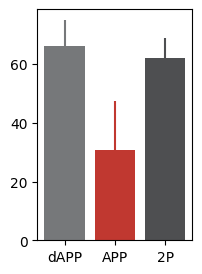

In [14]:
fig, ax = plt.subplots(figsize=(2,3)) 

ax.errorbar(x='dAPP', y=fit_dAPP[1], yerr=sigma_dAPP[1],
                fmt='none', capsize=5, capthick=0, color='#76787A',zorder=0,rasterized=True)
ax.bar(x='dAPP', height=fit_dAPP[1],color='#76787A',lw=2)
ax.errorbar(x='APP', y=fit_APP[1], yerr=sigma_APP[1],
                fmt='none', capsize=5, capthick=0, color='#C03830',zorder=0,rasterized=True)
ax.bar(x='APP', height=fit_APP[1],fill=True,color='#C03830',lw=2)
ax.errorbar(x='2P', y=fit_APP2P[1], yerr=sigma_APP2P[1],
                fmt='none', capsize=5, capthick=0, color='#4E4F51',zorder=0,rasterized=True)
ax.bar(x='2P', height=fit_APP2P[1],fill=True,color='#4E4F51',lw=2)
plt.locator_params(axis='y',nbins=4)

Text(0, 0.5, 'Rate constant')

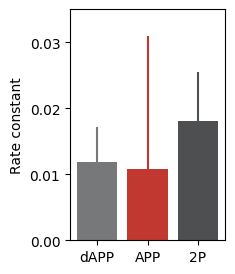

In [15]:
fig, ax = plt.subplots(figsize=(2,3)) 

ax.errorbar(x='dAPP', y=fit_dAPP[2], yerr=sigma_dAPP[2],
                fmt='none', capsize=5, capthick=0, color='#76787A',zorder=0,rasterized=True)
ax.bar(x='dAPP', height=fit_dAPP[2],color='#76787A',lw=2)
ax.errorbar(x='APP', y=fit_APP[2], yerr=sigma_APP[2],
                fmt='none', capsize=5, capthick=0, color='#C03830',zorder=0,rasterized=True)
ax.bar(x='APP', height=fit_APP[2],fill=True,color='#C03830',lw=2)
ax.errorbar(x='2P', y=fit_APP2P[2], yerr=sigma_APP2P[2],
                fmt='none', capsize=5, capthick=0, color='#4E4F51',zorder=0,rasterized=True)
ax.bar(x='2P', height=fit_APP2P[2],fill=True,color='#4E4F51',lw=2)
plt.ylim([0,0.035])
plt.locator_params(axis='y',nbins=4)
plt.ylabel('Rate constant')
#plt.savefig('FRAP/frap_v3_K.svg',bbox_inches='tight',transparent=True)

/var/folders/5x/p2xckt5d54zdnw2nd23zc4lm0000gp/T/ipykernel_28098/2422628595.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(),fontsize=16,rotation=0)
/var/folders/5x/p2xckt5d54zdnw2nd23zc4lm0000gp/T/ipykernel_28098/2422628595.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(),fontsize=16,rotation=0)


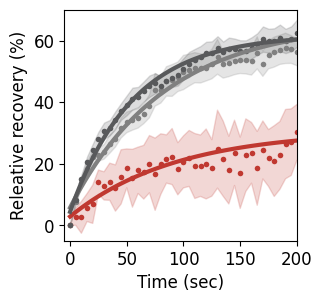

In [17]:
fig, ax = plt.subplots(figsize=(3,3)) 
sns.lineplot(x='time_post_bleach',y='norm_full',data=df,errorbar='se',hue='mdSAM',hue_order=['+','-','2P']
             ,palette=['#C03830','#808080','#58595B'],ax=ax,
             err_style='band',estimator=np.mean,lw=0,marker="o", markersize=4, markeredgewidth=.0, markeredgecolor="black")

plt.ylabel('Releative recovery (%)')
#ax.grid(zorder=0)

ax.set_ylim([-5,70])
ax.set_xlim([-5,200])
ax.locator_params(axis='y', nbins=4)
ax.set_xticklabels(ax.get_xticklabels(),fontsize=16,rotation=0)
ax.set_yticklabels(ax.get_yticklabels(),fontsize=16,rotation=0)

refDose = np.linspace(0,200,100)
plt.plot([ i for i in refDose],[prisim(i,*fit_dAPP) for i in refDose],lw=3,c='#808080')
plt.plot([ i for i in refDose],[prisim(i,*fit_APP) for i in refDose],lw=3,c='#C03830',ls='-')
plt.plot([ i for i in refDose],[prisim(i,*fit_APP2P) for i in refDose],lw=3,c='#58595B')
# plt.plot([ i for i in refDose],[prisim_dAPP_kata(i) for i in refDose],lw=2,c='k')
# plt.plot([ i for i in refDose],[prisim_APP_kata(i) for i in refDose],lw=2,c='k')
ax.set_ylabel('')
ax.set_xlabel('')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
ax.set_ylabel('Releative recovery (%)',fontsize=12)
ax.set_xlabel('Time (sec)',fontsize=12)
# ax.set_title('$y=A\\cdot (1-e^{-\\tau \\cdot t})$',fontsize=20)
# ax.text(62,75,"A =%.0f±%.0f\n$\\tau$ =%.3f±%.3f"%(A_dAPP,A_dAPP_error,tau_dAPP,tau_dAPP_error),fontsize=18)
# ax.text(62,-8,"A =%.0f±%.0f\n$\\tau$ =%.3f±%.3f"%(A_APP,A_APP_error,tau_APP,tau_APP_error),fontsize=18)


#ax.text(62,-8,"A = {} \n$\\tau$ = {}".format(APP_param_platu, APP_param_tau),fontsize=20)
ax.legend(title='mdSAM',title_fontsize=16,fontsize=12)
#ax.set_title('Structure',fontsize=16)
plt.legend([],frameon=False)
#plt.savefig('FRAP/frap_v3.svg',bbox_inches='tight',transparent=True)

In [18]:
from sklearn import preprocessing
min_max_scaler = preprocessing.MinMaxScaler()
df.drop_duplicates

<bound method DataFrame.drop_duplicates of        time  time_n  norm_full mdSAM  cell  time_post_bleach
0       9.0    15.0   0.000000     +     0               0.0
1      12.0    20.0   3.959933     +     0               5.0
2      15.0    25.0   5.622849     +     0              10.0
3      18.0    30.0  22.569293     +     0              15.0
4      21.0    35.0  22.222964     +     0              20.0
...     ...     ...        ...   ...   ...               ...
5260  225.0   225.0  66.277850    2P    30             210.0
5261  230.0   230.0  67.880075    2P    30             215.0
5262  235.0   235.0  67.615611    2P    30             220.0
5263  240.0   240.0  67.341961    2P    30             225.0
5264  245.0   245.0  66.518211    2P    30             230.0

[5265 rows x 6 columns]>

Text(0, 0.5, 'normilized recovery')

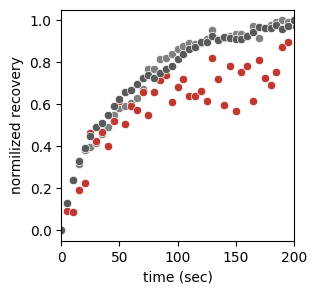

In [19]:
def flatten(xss):
    return [x for xs in xss for x in xs]
fig, ax = plt.subplots(figsize=(3,3)) 
sns.scatterplot(x=df[(df.mdSAM=='-')&(df.time_post_bleach.between(0,200))].time_post_bleach.drop_duplicates().to_list(),
                y=flatten(min_max_scaler.fit_transform(df[(df.mdSAM=='-')&(df.time_post_bleach.between(0,200))].loc[:,['time_post_bleach','norm_full']].groupby(['time_post_bleach']).mean())),color='#808080')
sns.scatterplot(x=df[(df.mdSAM=='+')&(df.time_post_bleach.between(0,200))].time_post_bleach.drop_duplicates().to_list(),
                y=flatten(min_max_scaler.fit_transform(df[(df.mdSAM=='+')&(df.time_post_bleach.between(0,200))].loc[:,['time_post_bleach','norm_full']].groupby(['time_post_bleach']).mean())),color='#C03830')
sns.scatterplot(x=df[(df.mdSAM=='2P')&(df.time_post_bleach.between(0,200))].time_post_bleach.drop_duplicates().to_list(),y=flatten(min_max_scaler.fit_transform(df[(df.mdSAM=='2P')&(df.time_post_bleach.between(0,200))].loc[:,['time_post_bleach','norm_full']].groupby(['time_post_bleach']).mean())),color='#58595B')
plt.xlim([0,200])
plt.xlabel('time (sec)')
plt.ylabel('normilized recovery')

In [20]:
df[df.mdSAM=='-'].pivot(columns='cell',index='time_post_bleach',values='norm_full').to_csv('Kata_fit_FRAP_dAPP.csv')
df[df.mdSAM=='+'].pivot(columns='cell',index='time_post_bleach',values='norm_full').to_csv('Kata_fit_FRAP_APP.csv')
df[df.mdSAM=='2P'].pivot(columns='cell',index='time_post_bleach',values='norm_full').to_csv('Kata_fit_FRAP_APP2P.csv')


<Axes: xlabel='time_post_bleach', ylabel='norm_full'>

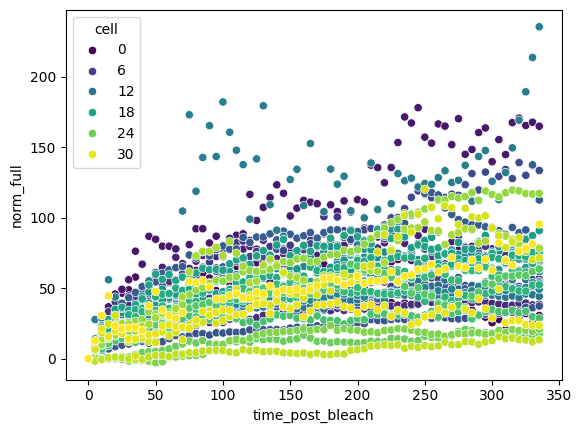

In [21]:
sns.scatterplot(x='time_post_bleach',y='norm_full',data=df[df.mdSAM=='-'],hue='cell',palette='viridis')

In [22]:
import warnings # To suppress some warnings
 
# Suppress the specific FutureWarning
warnings.filterwarnings("ignore", category=FutureWarning, module="seaborn")

In [23]:
l = []

y_std_app = df[df.mdSAM=='+'].loc[:,['time_post_bleach','norm_full']].groupby(['time_post_bleach']).std().norm_full/df[df.mdSAM=='+'].loc[:,['time_post_bleach','norm_full']].groupby(['time_post_bleach']).mean().norm_full
y_std_dapp = df[df.mdSAM=='-'].loc[:,['time_post_bleach','norm_full']].groupby(['time_post_bleach']).std().norm_full/df[df.mdSAM=='-'].loc[:,['time_post_bleach','norm_full']].groupby(['time_post_bleach']).mean().norm_full
y_std_app2p = df[df.mdSAM=='2P'].loc[:,['time_post_bleach','norm_full']].groupby(['time_post_bleach']).std().norm_full/df[df.mdSAM=='-'].loc[:,['time_post_bleach','norm_full']].groupby(['time_post_bleach']).mean().norm_full

for i in y_std_app.iloc[1:].index:
    l.append({'t':i,'val':100*y_std_app.loc[i],'mdSAM':'+'})
for i in y_std_dapp.iloc[1:].index:
    l.append({'t':i,'val':100*y_std_dapp.loc[i],'mdSAM':'-'})
for i in y_std_app2p.iloc[1:].index:
    l.append({'t':i,'val':100*y_std_app2p.loc[i],'mdSAM':'2P'})
sem_df = pd.DataFrame(l)


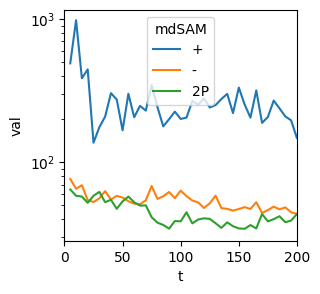

In [24]:
fig, ax = plt.subplots(figsize=(3,3)) 
sns.lineplot(x='t',y='val',data=sem_df,hue='mdSAM')
plt.yscale('log')
plt.xlim([0,200])
plt.savefig('frap_v3_CV.svg',bbox_inches='tight',transparent=True)